# 01 — Análise exploratória e caracterização temporal (+ atividade do Cap. 9)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

Este notebook responde à seção **2.1 do enunciado** (formulação do problema e caracterização temporal) e resolve o **exercício prático do Capítulo 9** (Nielsen, *Practical Time Series Analysis*) com o nosso próprio dataset:

| Pedido do exercício (notebook `04_2_cap9`) | Seção |
|---|---|
| 1. Preparar `time_series_data` e `labels_data` com o dataset do projeto | 2 |
| 2. Verificar estacionariedade; transformar e normalizar se necessário | 6 e 7 |
| 3. Extrair as características ergódicas (amplitude, % além de 1 desvio, assimetria, inclinação máxima) | 8 |
| 4. Treinar e comparar `RandomForestClassifier` × `XGBClassifier` | 9 |
| 5. Clusterização hierárquica para estudar o agrupamento das séries | 10 |

Entrada: `dados/minds_st.npz`, gerado pelo notebook 00.

## 1. Configuração

In [1]:
import sys, subprocess, importlib.util, warnings
from pathlib import Path

for pacote, nome_pip in [("tslearn", "tslearn"), ("xgboost", "xgboost"), ("statsmodels", "statsmodels")]:
    if importlib.util.find_spec(pacote) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", nome_pip], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, adjusted_rand_score
from sklearn.decomposition import PCA
import xgboost as xgb
from tslearn.metrics import cdist_dtw
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform, pdist

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de mudança de API do statsmodels
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

def salvar_fig(nome):
    plt.savefig(FIG / f"01_{nome}.png", bbox_inches="tight", dpi=150)

## 2. Os dados como séries temporais

Cada vídeo vira uma série temporal multivariada $\mathbf{X}_i \in \mathbb{R}^{T \times F}$, com $T = 32$ instantes e $F = 321$ atributos (coordenadas do corpo e das mãos), e recebe um rótulo $y_i \in \{1, \dots, 20\}$. É um problema de **classificação de séries temporais**: a série inteira (ou o seu início, na classificação antecipada) decide a palavra.

- `time_series_data` → `X` com forma (N, T, F)
- `labels_data` → `y` com forma (N,)

In [2]:
d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
cols, classes = d["cols"].astype(str), d["classes"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
mask, t0, t1 = d["mask"], d["t0"], d["t1"]
N, T, F = X.shape
CI = {c: i for i, c in enumerate(cols)}
bloco = pd.Series(cols).str.extract(r"^([a-z]+)")[0].to_numpy()
BLOCOS = ["pose", "dom", "outra", "fdom", "foutra"]

time_series_data, labels_data = X, y
print(f"time_series_data: {time_series_data.shape} | labels_data: {labels_data.shape} | classes: {len(classes)}")
print("vídeos por palavra: mín", np.bincount(y).min(), "| máx", np.bincount(y).max())

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

time_series_data: (1158, 32, 321) | labels_data: (1158,) | classes: 20
vídeos por palavra: mín 55 | máx 62


## 3. Caracterização temporal (seção 2.1 do enunciado)

### 3.1 Relação do problema com o tempo

- **Processo gerador:** um sinal de Libras é um movimento articulado com três fases em ordem fixa: **preparação** (a mão sai do repouso), **núcleo** (configuração de mão, locação e movimento que definem a palavra) e **retração**. O que distingue duas palavras muitas vezes não é a posição num instante, mas a **trajetória** e a **ordem** das posições.
- **Seta do tempo e causalidade:** a ordem não pode ser invertida. Há sinais que são quase o "inverso temporal" de outros (o mesmo caminho percorrido em sentido contrário), e o frame $t$ só depende do que veio antes. Por isso os modelos da classificação antecipada (notebook 05) usam apenas os frames já observados.
- **Auto-organização:** os frames vizinhos são muito correlacionados (seção 6: autocorrelação de lag 1 em torno de 0,8–0,9). A série não é um conjunto de medidas independentes: um modelo que embaralhe os instantes perde a informação principal.

### 3.2 Resolução, frequência de amostragem e comprimento

Os vídeos originais do MINDS têm 1920×1080 pixels e **~30 fps**. A medição abaixo usa uma amostra de 72 vídeos (6 por sinalizante), lida direto dos zips originais.

In [3]:
dur = pd.read_csv(DADOS / "duracoes_amostra_minds.csv")
print(f"amostra: {len(dur)} vídeos | fps médio: {dur.fps.mean():.2f} | duração: média {dur.duracao_s.mean():.2f} s, "
      f"mín {dur.duracao_s.min():.2f} s, máx {dur.duracao_s.max():.2f} s")

# o pipeline amostra 32 frames uniformes do vídeo inteiro, corta o repouso (frames t0..t1 desses 32)
# e reamostra o trecho ativo de volta para 32 instantes
ativos = t1 - t0 + 1
dur_ativa = dur.duracao_s.mean() * (t1 - t0) / (T - 1)         # segundos do trecho ativo (estimativa com a duração média)
dt = dur_ativa / (T - 1)                                       # intervalo entre instantes da série final
print(f"frames ativos (dos 32 amostrados): mediana {np.median(ativos):.0f}")
print(f"trecho ativo estimado: mediana {np.median(dur_ativa):.2f} s | intervalo entre instantes: mediana {np.median(dt) * 1000:.0f} ms "
      f"(~{1 / np.median(dt):.1f} Hz)")
print(f"comprimento histórico: {N} séries × {T} instantes = {N * T:,} instantes, ~{N * dur.duracao_s.mean() / 60:.0f} min de vídeo")

amostra: 72 vídeos | fps médio: 30.21 | duração: média 4.63 s, mín 2.90 s, máx 6.60 s
frames ativos (dos 32 amostrados): mediana 22
trecho ativo estimado: mediana 3.14 s | intervalo entre instantes: mediana 101 ms (~9.9 Hz)
comprimento histórico: 1158 séries × 32 instantes = 37,056 instantes, ~89 min de vídeo


| Propriedade | Valor |
|---|---|
| Frequência original | ~30 fps (vídeo) |
| Amostragem da série | 32 instantes por sinal, cobrindo só o trecho ativo; intervalo de ~0,1 s (~10 Hz), variável de vídeo para vídeo |
| Comprimento | 32 instantes por série; 1.158 séries (~1,5 h de vídeo) |
| Natureza | **Multivariada**, 321 canais (5 blocos do corpo e das mãos) |
| Covariáveis exógenas conhecidas antes | **Nenhuma.** A identidade do sinalizante existe nos dados, mas não está disponível para uma pessoa nova e não é usada como entrada |
| Tipo de problema | **Classificação** (20 classes) |
| Horizonte | Adaptação do horizonte de previsão: **classificação antecipada**, decidindo a palavra com os primeiros 25%, 50%, 75% e 100% dos instantes (notebook 05) |

A reamostragem para 32 instantes torna a duração do sinal **invariante**: um sinalizante rápido e um lento produzem séries do mesmo tamanho. O preço é que o instante $t$ não corresponde a um tempo absoluto fixo; ele é uma fração do sinal.

## 4. Visualização das séries

Depois do espelhamento, a mão dominante fica sempre no lado "direito" do corpo: o punho dominante é o ponto `pose16`. O eixo $y$ cresce para baixo (coordenadas de imagem), então valores menores significam a mão mais alta.

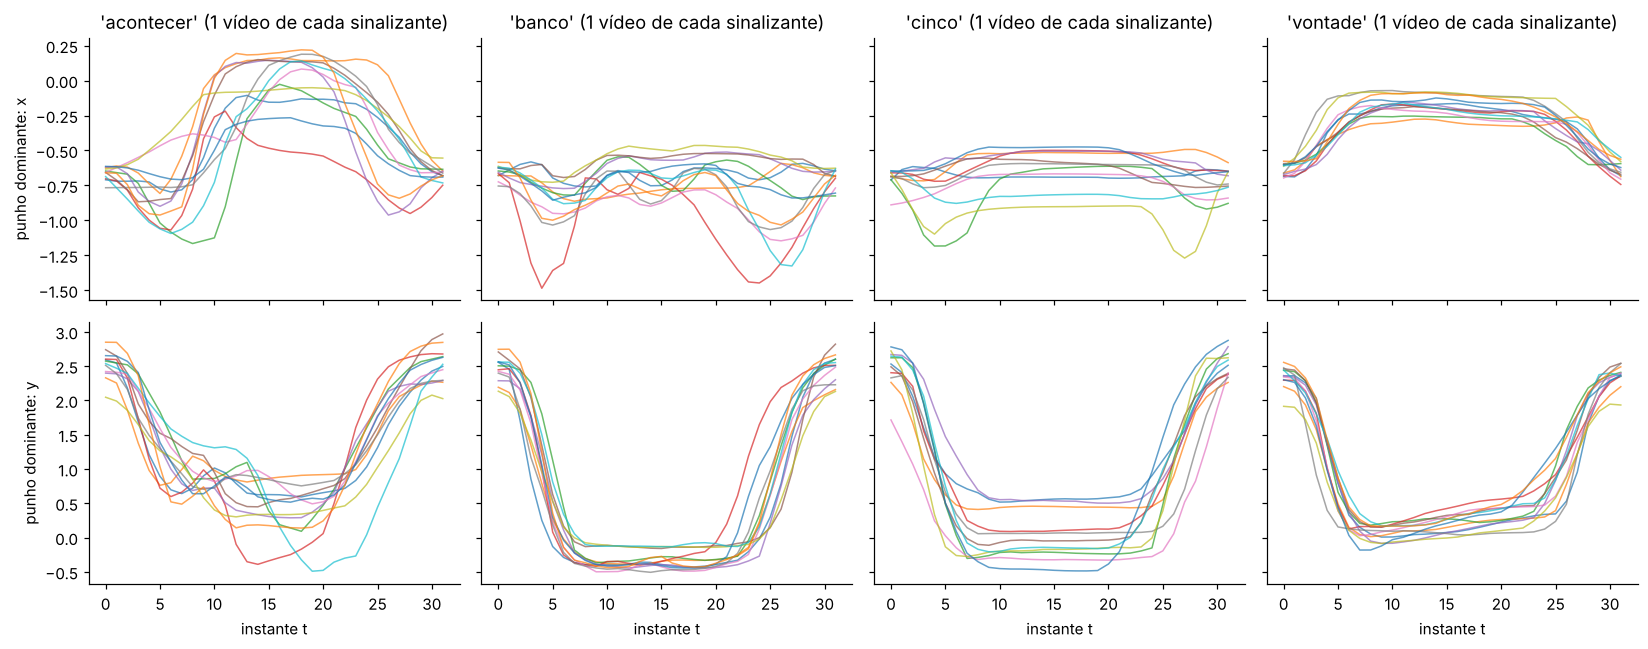

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6), sharex=True, sharey="row")
palavras = ["acontecer", "banco", "cinco", "vontade"]
for j, p in enumerate(palavras):
    c = list(classes).index(p)
    for s in range(1, 13):
        i = np.where((y == c) & (sinalizante == s))[0]
        if len(i):
            axs[0, j].plot(X[i[0], :, CI["pose16_x"]], alpha=.7, lw=1)
            axs[1, j].plot(X[i[0], :, CI["pose16_y"]], alpha=.7, lw=1)
    axs[0, j].set_title(f"'{p}' (1 vídeo de cada sinalizante)")
axs[0, 0].set_ylabel("punho dominante: x"); axs[1, 0].set_ylabel("punho dominante: y")
for a in axs[1]: a.set_xlabel("instante t")
plt.tight_layout(); salvar_fig("trajetorias_punho"); plt.show()

Cada palavra tem uma "forma de onda" típica, e os 12 sinalizantes seguem essa forma com **deslocamentos de fase e de amplitude**: uns começam o movimento antes, outros fazem o gesto maior. É exatamente o tipo de variação que o DTW (seção 10) e as convoluções e recorrências (notebook 03) tentam absorver.

O mapa de calor abaixo mostra **uma série inteira** (os 321 canais ao longo do tempo), padronizada por canal só para a visualização.

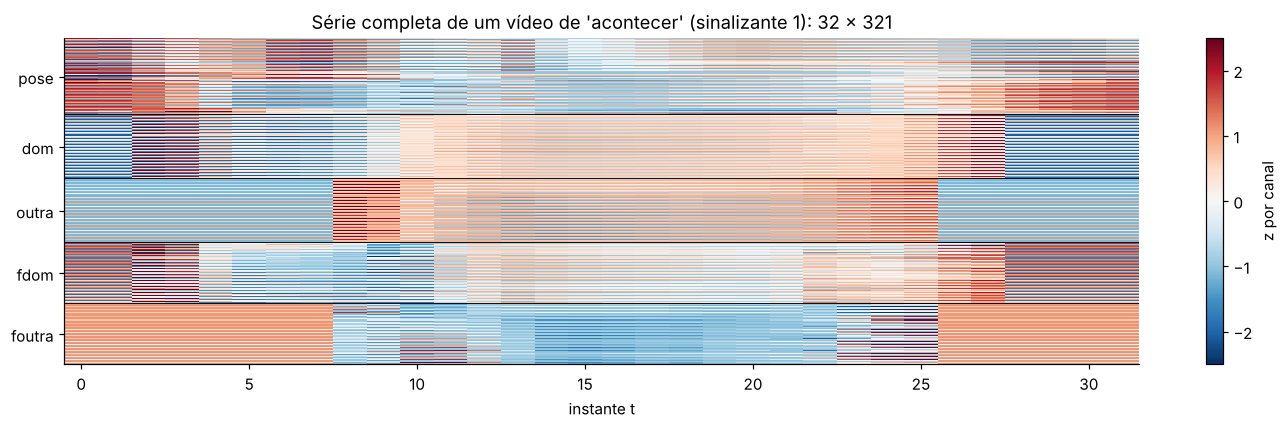

In [5]:
i = np.where(y == list(classes).index("acontecer"))[0][0]
Z = (X[i] - X[i].mean(0)) / (X[i].std(0) + 1e-6)
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(Z.T, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5, interpolation="nearest")
lim = np.cumsum([0] + [int((bloco == b).sum()) for b in BLOCOS])
ax.set_yticks((lim[:-1] + lim[1:]) / 2, BLOCOS); [ax.axhline(l - .5, color="k", lw=.6) for l in lim[1:-1]]
ax.set_xlabel("instante t"); ax.set_title(f"Série completa de um vídeo de '{classes[y[i]]}' (sinalizante {sinalizante[i]}): 32 × 321")
plt.colorbar(im, ax=ax, label="z por canal"); plt.tight_layout(); salvar_fig("serie_heatmap"); plt.show()

## 5. Ruído do MediaPipe e conteúdo em frequência

O MediaPipe estima os pontos frame a frame, de forma independente. Isso produz um **tremor** de alta frequência que não é movimento real. A figura separa um canal da ponta do indicador em **tendência** (média móvel centrada de 3 instantes) e **resíduo**: é a decomposição que o estudo de ablação vai testar (notebook 04).

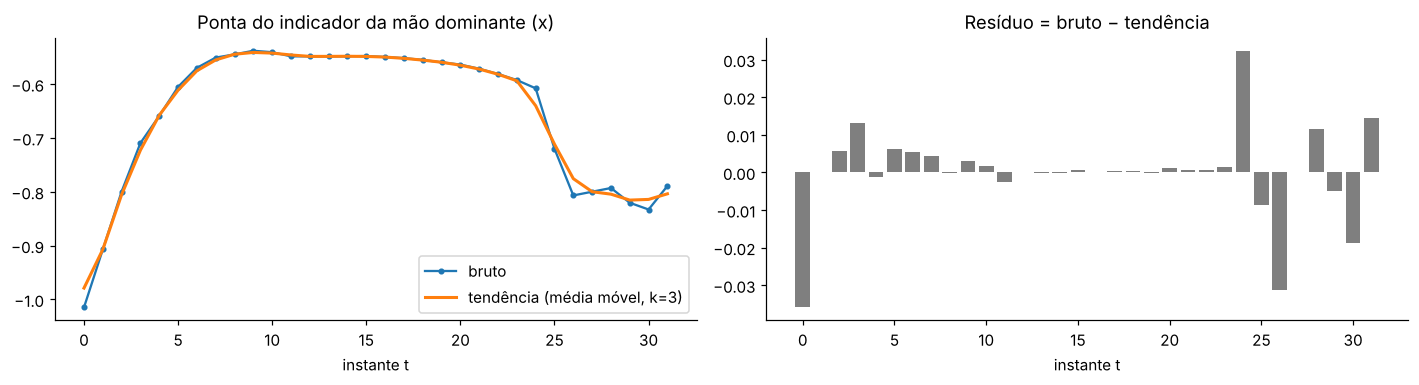

In [6]:
def media_movel(s, k=3):
    # média móvel centrada, com as bordas tratadas pela própria janela disponível
    pad = np.pad(s, (k // 2, k // 2), mode="edge")
    return np.convolve(pad, np.ones(k) / k, mode="valid")

# um vídeo com a mão dominante detectada em todos os instantes (para ver o tremor, e não falhas de detecção)
cand = np.where((y == list(classes).index("cinco")) & mask[:, :, 1].all(1))[0]
res_cand = [np.abs(X[j, :, CI["dom8_x"]] - media_movel(X[j, :, CI["dom8_x"]])).mean() for j in cand]
i = cand[np.argsort(res_cand)[len(cand) // 2]]                  # tremor típico (mediana), não o pior caso
s = X[i, :, CI["dom8_x"]]
tend = media_movel(s)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
axs[0].plot(s, "o-", ms=3, label="bruto"); axs[0].plot(tend, lw=2, label="tendência (média móvel, k=3)")
axs[0].set_title("Ponta do indicador da mão dominante (x)"); axs[0].legend(); axs[0].set_xlabel("instante t")
axs[1].bar(range(T), s - tend, color="tab:gray"); axs[1].set_title("Resíduo = bruto − tendência"); axs[1].set_xlabel("instante t")
plt.tight_layout(); salvar_fig("decomposicao_media_movel"); plt.show()

Para ver onde está a energia do sinal, calculamos a **FFT** de cada canal (32 instantes → 17 frequências, de 0 até a frequência de Nyquist) e somamos o espectro de potência por bloco do corpo.

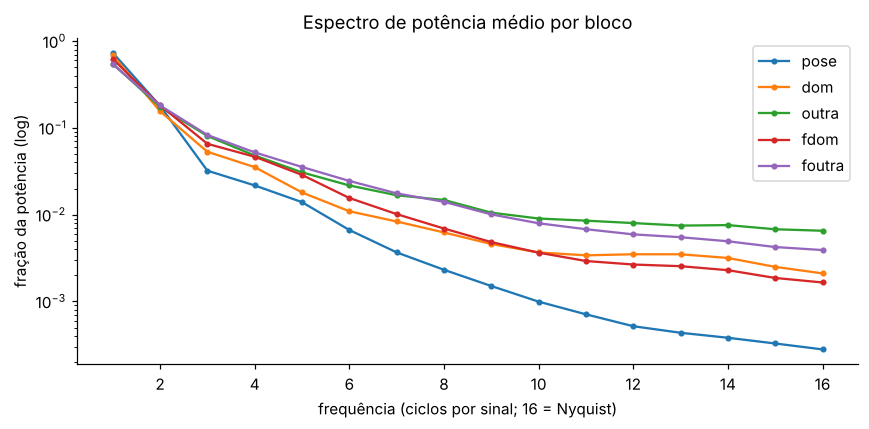

,baixas (1–3 ciclos) %,médias (4–8) %,altas (9–16) %
bloco,,,
pose,94.699997,4.8,0.5
dom,89.500000,7.9,2.6
outra,80.400002,13.2,6.4
fdom,87.000000,10.8,2.2
foutra,80.699997,14.4,4.9


instantes sem a mão detectada (canais zerados): dominante 10.8% | outra mão 42.4%


In [7]:
P = np.abs(np.fft.rfft(X - X.mean(1, keepdims=True), axis=1)) ** 2        # (N, 17, F)
freq = np.arange(P.shape[1])                                               # em ciclos por sinal
linhas = []
fig, ax = plt.subplots(figsize=(8, 4))
for b in BLOCOS:
    p = P[:, :, bloco == b].sum((0, 2)); p = p / p.sum()
    ax.semilogy(freq[1:], p[1:], "o-", ms=3, label=b)
    linhas.append(dict(bloco=b, **{"baixas (1–3 ciclos) %": 100 * p[1:4].sum(), "médias (4–8) %": 100 * p[4:9].sum(),
                                   "altas (9–16) %": 100 * p[9:].sum()}))
ax.set_xlabel("frequência (ciclos por sinal; 16 = Nyquist)"); ax.set_ylabel("fração da potência (log)")
ax.set_title("Espectro de potência médio por bloco"); ax.legend(); plt.tight_layout(); salvar_fig("espectro_blocos"); plt.show()
espectro = pd.DataFrame(linhas).set_index("bloco").round(1)
display(espectro)

zeros = {b: float((X[:, :, bloco == b] == 0).all(-1).mean()) for b in ["dom", "outra"]}
print(f"instantes sem a mão detectada (canais zerados): dominante {100 * zeros['dom']:.1f}% | outra mão {100 * zeros['outra']:.1f}%")

**Leitura:**

- Entre 80% e 95% da energia está nas **3 primeiras frequências**: o sinal de Libras é um movimento lento e suave em relação à taxa de amostragem.
- As **mãos** têm bem mais energia em alta frequência do que o corpo (`pose`). Parte disso é o tremor do MediaPipe, e parte vem das **falhas de detecção**: quando a mão some, os canais viram 0, o que cria "degraus" abruptos. Isso acontece em ~11% dos instantes da mão dominante e em ~42% da outra mão (que muitas vezes fica fora do quadro ou parada).
- Isso justifica as duas técnicas da ablação: a **decomposição por média móvel** (separa tendência e tremor) e a **filtragem no domínio da frequência** (FFT, mantendo só as baixas frequências). A pergunta do notebook 04 é se remover essa energia de alta frequência ajuda a reconhecer pessoas novas, ou se ela carrega informação útil (movimentos rápidos dos dedos).

## 6. Estacionariedade (exercício, item 2)

Seguindo o notebook `03_1_stationarity`, aplicamos aos canais principais:

1. **estatísticas por partes**: média e variância da 1ª e da 2ª metade de cada série;
2. **teste ADF** (Dickey-Fuller aumentado; $H_0$: raiz unitária, ou seja, *não* estacionária);
3. **teste KPSS** ($H_0$: estacionária), que inverte a hipótese do ADF e serve de contraprova.

Os testes são feitos **série a série** (cada vídeo), com no máximo 3 defasagens, porque cada série tem só 32 pontos.

In [8]:
CANAIS = {"pose16_x": "punho dom. x", "pose16_y": "punho dom. y", "dom8_x": "ponta do indicador x", "fdom8_y": "formato: indicador y"}

def testes(serie):
    if serie.std() < 1e-6:
        return np.nan, np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # o KPSS avisa quando o p-valor passa dos limites da tabela (0,01 ou 0,1)
        return adfuller(serie, maxlag=3, autolag=None)[1], kpss(serie, nlags=3)[1]

linhas = []
for c, nome in CANAIS.items():
    S = X[:, :, CI[c]]
    for transf, M in [("nível", S), ("1ª diferença", np.diff(S, axis=1))]:
        pv = np.array([testes(s) for s in M])
        ok = ~np.isnan(pv[:, 0])
        m1, m2 = M[:, : M.shape[1] // 2], M[:, M.shape[1] // 2:]
        linhas.append({"canal": nome, "série": transf,
                       "ADF rejeita H0 (estacionária) %": 100 * (pv[ok, 0] < .05).mean(),
                       "KPSS rejeita H0 (não estac.) %": 100 * (pv[ok, 1] < .05).mean(),
                       "|Δ média| metades / desvio": np.median(np.abs(m1.mean(1) - m2.mean(1)) / (M.std(1) + 1e-6)),
                       "razão de variâncias metades": np.median((m2.var(1) + 1e-9) / (m1.var(1) + 1e-9))})
estac = pd.DataFrame(linhas).set_index(["canal", "série"]).round(2)
display(estac)
estac.to_csv(RES / "01_estacionariedade.csv")

ADF rejeita H0 (estacionária) %  \
canal                série                                           
punho dom. x         nível                                    4.15   
                     1ª diferença                            17.10   
punho dom. y         nível                                    0.09   
                     1ª diferença                            30.66   
ponta do indicador x nível                                   11.05   
                     1ª diferença                            34.28   
formato: indicador y nível                                   13.82   
                     1ª diferença                            46.55   

                                   KPSS rejeita H0 (não estac.) %  \
canal                série                                          
punho dom. x         nível                                   5.27   
                     1ª diferença                           48.62   
punho dom. y         nível                                   0.09   
                     1ª diferença                           92.49   
ponta do indicador x nível                                   4.49   
                     1ª diferença                           25.56   
formato: indicador y nível                                   0.35   
                     1ª diferença                           18.39   

                                   |Δ média| metades / desvio  \
canal                série                                      
punho dom. x         nível                               0.39   
                     1ª diferença                        1.05   
punho dom. y         nível                               0.21   
                     1ª diferença                        1.22   
ponta do indicador x nível                               0.41   
                     1ª diferença                        0.53   
formato: indicador y nível                               0.32   
                     1ª diferença                        0.56   

                                   razão de variâncias metades  
canal                série                                      
punho dom. x         nível                                1.11  
                     1ª diferença                         0.96  
punho dom. y         nível                                1.00  
                     1ª diferença                         0.60  
ponta do indicador x nível                                1.24  
                     1ª diferença                         0.86  
formato: indicador y nível                                1.05  
                     1ª diferença                         0.69

**Leitura:**

- **Em nível**, o ADF quase nunca rejeita a raiz unitária (a série *parece* não estacionária), enquanto o KPSS quase nunca rejeita a estacionariedade (a série *parece* estacionária). Os dois testes "ficam com a própria hipótese nula": é o sintoma clássico de **baixo poder estatístico** com séries de só 32 pontos. Nenhum dos dois tem evidência suficiente.
- As **estatísticas por partes** ajudam a entender o porquê: em nível, as duas metades têm médias parecidas (diferença de 0,2–0,4 desvio) porque o sinal **sai do repouso e volta a ele**. A posição não "deriva"; ela faz um percurso de ida e volta.
- Na **1ª diferença** (velocidade), o ADF rejeita a raiz unitária com mais frequência, mas o KPSS passa a rejeitar a estacionariedade em muitas séries (até 92% no punho, eixo y), e as médias das metades ficam **opostas** (mais de 1 desvio de diferença): a 1ª metade é a velocidade de ida, a 2ª é a de volta. A diferenciação não torna o sinal estacionário; ela só troca uma forma transitória (posição) por outra (perfil de velocidade).

**Consequência para o trabalho:** cada série é um **evento transitório**, e não um processo em regime permanente. Em nenhuma das transformações ela é estacionária no sentido usual, e isso não é um defeito: ao contrário da previsão, na classificação essa forma *é* a informação que distingue as palavras e não deve ser removida. O que importa é a **estacionariedade entre séries**: a distribuição dos atributos precisa ser parecida entre os sinalizantes do treino e os do teste. É isso que a normalização pelo corpo (notebook 00) e o z-score ajustado no treino (seção 7) procuram. A 1ª diferença entra como atributo (inclinação máxima, seção 8).

### 6.1 Autocorrelação (ACF e PACF)

A média da ACF e da PACF de todas as séries mostra quanto cada instante "lembra" dos anteriores.

punho dom. y: ACF lag 1 = 0.87 | PACF lag 1 = 0.90, lag 2 = -0.41


ponta do indicador x: ACF lag 1 = 0.80 | PACF lag 1 = 0.82, lag 2 = -0.47


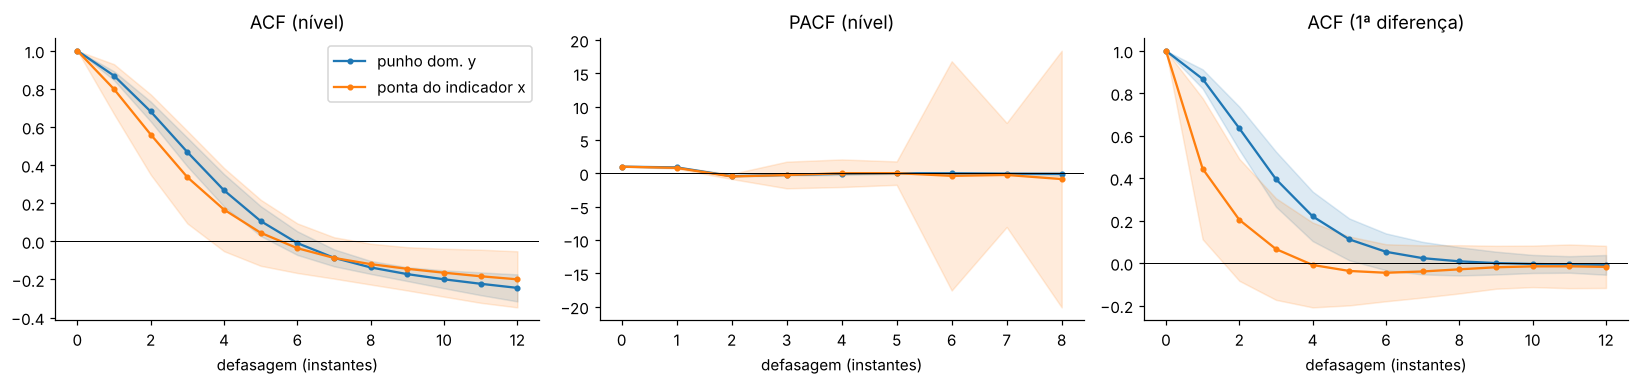

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for c, cor in [("pose16_y", "tab:blue"), ("dom8_x", "tab:orange")]:
    S = X[:, :, CI[c]]; S = S[S.std(1) > 1e-6]
    A = np.array([acf(s, nlags=12) for s in S]); Pp = np.array([pacf(s, nlags=8) for s in S])
    Ad = np.array([acf(np.diff(s), nlags=12) for s in S])
    for ax, M, tit in [(axs[0], A, "ACF (nível)"), (axs[1], Pp, "PACF (nível)"), (axs[2], Ad, "ACF (1ª diferença)")]:
        m, sd = M.mean(0), M.std(0)
        ax.plot(m, "o-", color=cor, ms=3, label=CANAIS[c]); ax.fill_between(range(len(m)), m - sd, m + sd, color=cor, alpha=.15)
        ax.set_title(tit); ax.axhline(0, color="k", lw=.6); ax.set_xlabel("defasagem (instantes)")
    print(f"{CANAIS[c]}: ACF lag 1 = {A[:, 1].mean():.2f} | PACF lag 1 = {Pp[:, 1].mean():.2f}, lag 2 = {Pp[:, 2].mean():.2f}")
axs[0].legend(); plt.tight_layout(); salvar_fig("acf_pacf"); plt.show()

A ACF decai lentamente e a PACF tem um pico forte e positivo no lag 1 seguido de um valor negativo no lag 2: comportamento de um processo autorregressivo de 2ª ordem, típico de uma **trajetória suave que sobe e depois desce** (ida e volta). A forte dependência entre instantes vizinhos justifica modelos que exploram a ordem (CNN-1D, WaveNet, RNN, LSTM, GRU) e mostra por que embaralhar os instantes, ou tratá-los como colunas independentes, desperdiça estrutura.

## 7. Normalização sem vazamento (exercício, item 2)

As coordenadas já estão normalizadas pelo corpo de cada pessoa (notebook 00). Para os modelos, ainda aplicamos o **z-score por canal**, com média e desvio **calculados só no treino** de cada rodada. O gráfico compara a distribuição de um canal no treino e no teste da rodada 0: a diferença entre as curvas é o desvio causado por **pessoas diferentes**, que nenhuma normalização ajustada no treino pode esconder.

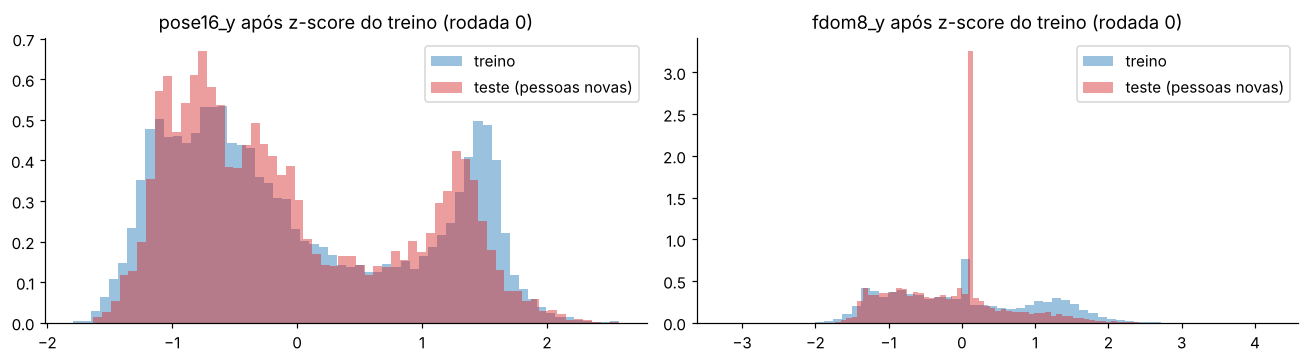

In [10]:
tr, va, te = particao(0)
mu = X[tr].reshape(-1, F).mean(0); sd = X[tr].reshape(-1, F).std(0) + 1e-6
Xz = (X - mu) / sd
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, c in zip(axs, ["pose16_y", "fdom8_y"]):
    for nome, i_, cor in [("treino", tr, "tab:blue"), ("teste (pessoas novas)", te, "tab:red")]:
        ax.hist(Xz[i_, :, CI[c]].ravel(), bins=60, density=True, alpha=.45, color=cor, label=nome)
    ax.set_title(f"{c} após z-score do treino (rodada 0)"); ax.legend()
plt.tight_layout(); salvar_fig("zscore_treino_teste"); plt.show()

## 8. Características ergódicas (exercício, item 3)

O Capítulo 9 propõe resumir cada série em estatísticas que não dependem do instante exato (características **ergódicas**, que valem para a série como um todo). Para cada um dos 321 canais calculamos:

| Característica | Fórmula | O que captura no sinal |
|---|---|---|
| Amplitude | $\max_t x_t - \min_t x_t$ | tamanho do gesto naquele canal |
| % além de 1 desvio | $\frac{1}{T}\sum_t \mathbb{1}(\lvert x_t-\bar x\rvert > s)$ | se o movimento é concentrado (picos) ou espalhado |
| Assimetria | $\frac{1}{T}\sum_t \left(\frac{x_t-\bar x}{s}\right)^3$ | se o canal passa mais tempo de um lado da média |
| Inclinação máxima | $\max_t \lvert x_{t+1}-x_t\rvert$ | velocidade máxima (usa a 1ª diferença) |

São 4 × 321 = **1.284 características por vídeo**. O cálculo usa só a própria série, então não há vazamento entre treino e teste.

In [11]:
def caracteristicas_ergodicas(X):
    mu, sd = X.mean(1, keepdims=True), X.std(1, keepdims=True)
    amplitude = X.max(1) - X.min(1)
    alem_1dp = (np.abs(X - mu) > sd).mean(1)
    ok = sd[:, 0] > 1e-6                                     # canal constante (ex.: mão ausente o tempo todo) -> assimetria 0
    assimetria = np.where(ok, (((X - mu) / np.where(sd > 1e-6, sd, 1)) ** 3).mean(1), 0.0)
    inclinacao_max = np.abs(np.diff(X, axis=1)).max(1)
    E = np.concatenate([amplitude, alem_1dp, assimetria, inclinacao_max], axis=1)
    nomes = [f"{t}|{c}" for t in ["amplitude", "alem_1dp", "assimetria", "inclinacao_max"] for c in cols]
    return E.astype(np.float32), np.array(nomes)

E, nomes_E = caracteristicas_ergodicas(X)
print("matriz de características:", E.shape)
display(pd.DataFrame(E[:3, ::321], columns=[n.split("|")[0] for n in nomes_E[::321]], index=[f"vídeo {k}" for k in range(3)]).round(3))

matriz de características: (1158, 1284)


,amplitude,alem_1dp,assimetria,inclinacao_max
vídeo 0,0.036,0.250,0.779,0.008
vídeo 1,0.011,0.156,1.300,0.003
vídeo 2,0.012,0.469,0.391,0.003


## 9. Random Forest × XGBoost (exercício, item 4)

Protocolo (o mesmo de todos os notebooks): as **4 rodadas por sinalizante** do notebook 00. Em cada rodada:

- **Random Forest:** 500 árvores, sem ajuste fino (a validação não é usada);
- **XGBoost:** até 1.000 rodadas de *boosting*, com **parada antecipada na validação** (50 rodadas sem melhora). Assim o teste nunca participa de nenhuma escolha;
- **Classe majoritária:** a baseline ingênua obrigatória do enunciado.

Métricas, também as do enunciado para classificação: **acurácia**, **acurácia balanceada** e **F1 macro** (média do F1 das 20 palavras).

In [12]:
def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))

resultados, previsoes, importancias = [], {"rf": np.zeros(N, int), "xgb": np.zeros(N, int)}, {"rf": [], "xgb": []}
for k in range(4):
    tr, va, te = particao(k)
    maj = DummyClassifier(strategy="most_frequent").fit(E[tr], y[tr])
    resultados.append(dict(rodada=k, modelo="Classe majoritária", **metricas(y[te], maj.predict(E[te]))))

    rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED).fit(E[tr], y[tr])
    previsoes["rf"][te] = rf.predict(E[te]); importancias["rf"].append(rf.feature_importances_)
    resultados.append(dict(rodada=k, modelo="Random Forest", **metricas(y[te], previsoes["rf"][te])))

    xg = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.3,
                           tree_method="hist", early_stopping_rounds=50, eval_metric="mlogloss", random_state=SEED, n_jobs=-1)
    xg.fit(E[tr], y[tr], eval_set=[(E[va], y[va])], verbose=False)
    previsoes["xgb"][te] = xg.predict(E[te]); importancias["xgb"].append(xg.feature_importances_)
    resultados.append(dict(rodada=k, modelo="XGBoost", melhor_iteracao=xg.best_iteration, **metricas(y[te], previsoes["xgb"][te])))
    print(f"rodada {k}: RF {resultados[-2]['f1_macro']:.3f} | XGB {resultados[-1]['f1_macro']:.3f} (F1 macro; {xg.best_iteration} rodadas)")

res = pd.DataFrame(resultados)
res.to_csv(RES / "01_rf_xgb_por_rodada.csv", index=False)
resumo = res.groupby("modelo")[["acuracia", "acuracia_balanceada", "f1_macro"]].agg(["mean", "std"]).round(3)
display(resumo)
resumo.to_csv(RES / "01_rf_xgb_resumo.csv")

rodada 0: RF 0.690 | XGB 0.642 (F1 macro; 248 rodadas)


rodada 1: RF 0.771 | XGB 0.756 (F1 macro; 308 rodadas)


rodada 2: RF 0.725 | XGB 0.733 (F1 macro; 135 rodadas)


rodada 3: RF 0.784 | XGB 0.763 (F1 macro; 376 rodadas)


acuracia        acuracia_balanceada        f1_macro       
                       mean    std                mean    std     mean    std
modelo                                                                       
Classe majoritária    0.052  0.002               0.050  0.000    0.005  0.000
Random Forest         0.755  0.031               0.752  0.037    0.743  0.043
XGBoost               0.739  0.036               0.735  0.045    0.723  0.056

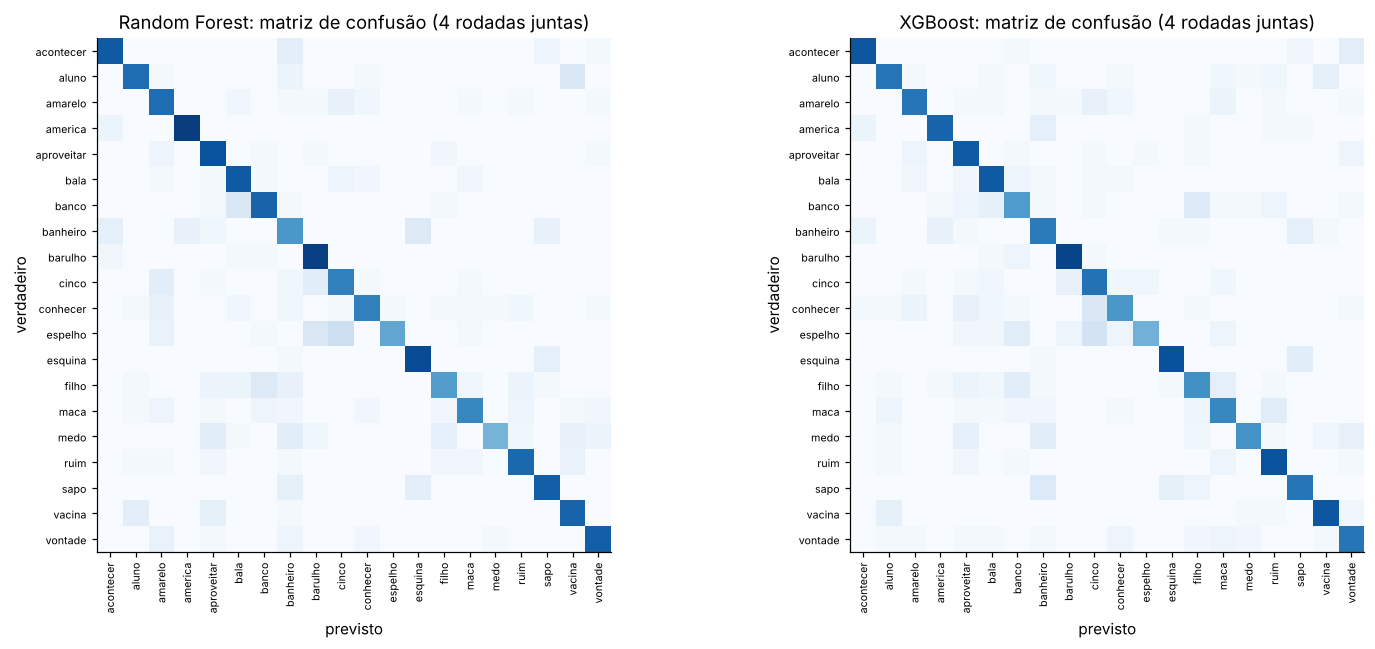

palavras mais difíceis (F1 do RF): {'banheiro': 0.52, 'filho': 0.63, 'medo': 0.63, 'cinco': 0.67}
palavras mais fáceis  (F1 do RF): {'america': 0.94, 'esquina': 0.84, 'acontecer': 0.83, 'barulho': 0.83}


In [13]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, m, tit in [(axs[0], "rf", "Random Forest"), (axs[1], "xgb", "XGBoost")]:
    cm = confusion_matrix(y, previsoes[m], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(20), classes, rotation=90, fontsize=7); ax.set_yticks(range(20), classes, fontsize=7)
    ax.set_title(f"{tit}: matriz de confusão (4 rodadas juntas)"); ax.set_xlabel("previsto"); ax.set_ylabel("verdadeiro")
plt.tight_layout(); salvar_fig("confusao_rf_xgb"); plt.show()

f1_palavra = pd.DataFrame({m: f1_score(y, previsoes[m], average=None) for m in previsoes}, index=classes).round(2)
print("palavras mais difíceis (F1 do RF):", f1_palavra.rf.nsmallest(4).to_dict())
print("palavras mais fáceis  (F1 do RF):", f1_palavra.rf.nlargest(4).to_dict())

### 9.1 Quais características mais pesam?

Somamos a importância das características por **bloco do corpo** e por **tipo de característica**.

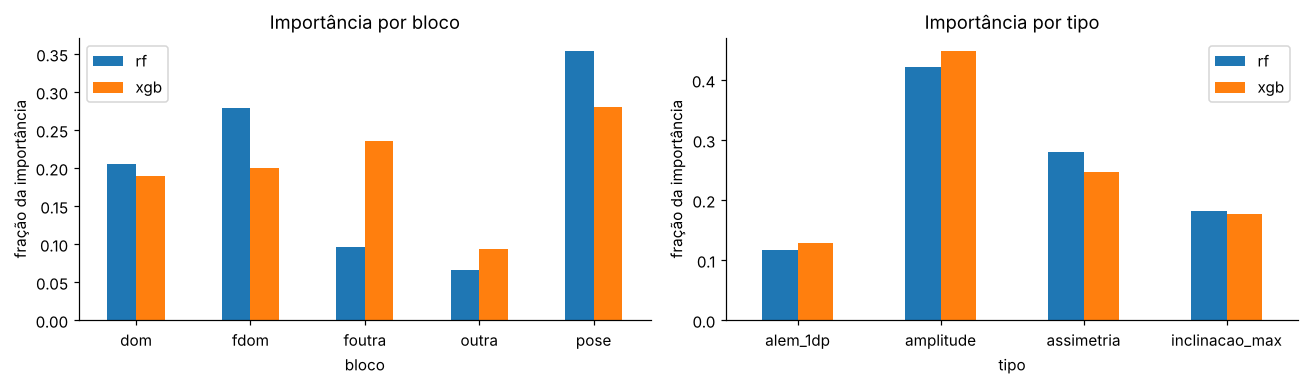

10 características mais importantes (RF):
amplitude|pose14_y         0.0094
amplitude|pose16_y         0.0066
amplitude|pose14_x         0.0061
amplitude|pose18_y         0.0061
amplitude|pose16_x         0.0058
amplitude|fdom20_x         0.0057
amplitude|fdom16_x         0.0056
amplitude|pose20_y         0.0054
inclinacao_max|pose14_y    0.0053
inclinacao_max|pose14_x    0.0053


In [14]:
imp = pd.DataFrame({m: np.mean(importancias[m], axis=0) for m in importancias}, index=nomes_E)
imp["tipo"] = [n.split("|")[0] for n in imp.index]
imp["bloco"] = [pd.Series([n.split("|")[1]]).str.extract(r"^([a-z]+)")[0][0] for n in imp.index]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, chave in zip(axs, ["bloco", "tipo"]):
    g = imp.groupby(chave)[["rf", "xgb"]].sum()
    g = g / g.sum()
    g.plot.bar(ax=ax, rot=0); ax.set_ylabel("fração da importância"); ax.set_title(f"Importância por {chave}")
plt.tight_layout(); salvar_fig("importancia_caracteristicas"); plt.show()
print("10 características mais importantes (RF):"); print(imp.rf.nlargest(10).round(4).to_string())

## 10. Clusterização hierárquica com DTW (exercício, item 5)

Seguindo o Cap. 9, comparamos o agrupamento hierárquico com duas medidas de distância:

- **Euclidiana:** compara os instantes um a um (o instante 10 de uma série com o instante 10 da outra);
- **DTW (*Dynamic Time Warping*):** alinha as séries no tempo antes de comparar, tolerando um sinalizante que começa antes ou se move mais devagar.

Usamos uma **amostra estratificada** de 8 vídeos por palavra (160 séries) e a trajetória 2D do punho e da ponta do indicador da mão dominante (4 canais, padronizados). O **índice de Rand ajustado (ARI)** mede quanto os grupos encontrados coincidem com as palavras: 0 = acaso, 1 = perfeito.

In [15]:
rng = np.random.default_rng(SEED)
amostra = np.concatenate([rng.choice(np.where(y == c)[0], 8, replace=False) for c in range(20)])
canais_traj = [CI[c] for c in ["pose16_x", "pose16_y", "dom8_x", "dom8_y"]]
S = X[amostra][:, :, canais_traj]
S = (S - S.mean((0, 1))) / S.std((0, 1))

D_dtw = cdist_dtw(S)
D_euc = squareform(pdist(S.reshape(len(S), -1)))
ari = []
for nome, D in [("DTW", D_dtw), ("Euclidiana", D_euc)]:
    for metodo in ["average", "complete"]:
        Z = linkage(squareform(D, checks=False), metodo)
        ari.append(dict(distancia=nome, ligacao=metodo, ARI=adjusted_rand_score(y[amostra], fcluster(Z, 20, "maxclust"))))
ari = pd.DataFrame(ari).round(3)
display(ari.pivot(index="distancia", columns="ligacao", values="ARI"))
ari.to_csv(RES / "01_cluster_ari.csv", index=False)

ligacao,average,complete
distancia,,
DTW,0.131,0.178
Euclidiana,0.104,0.144


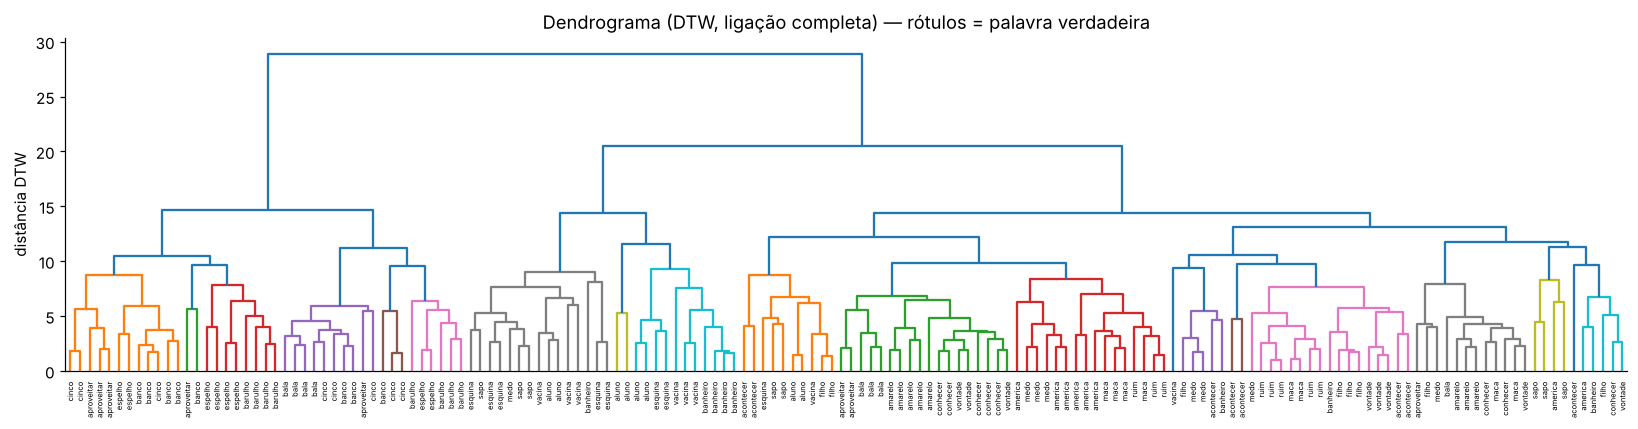

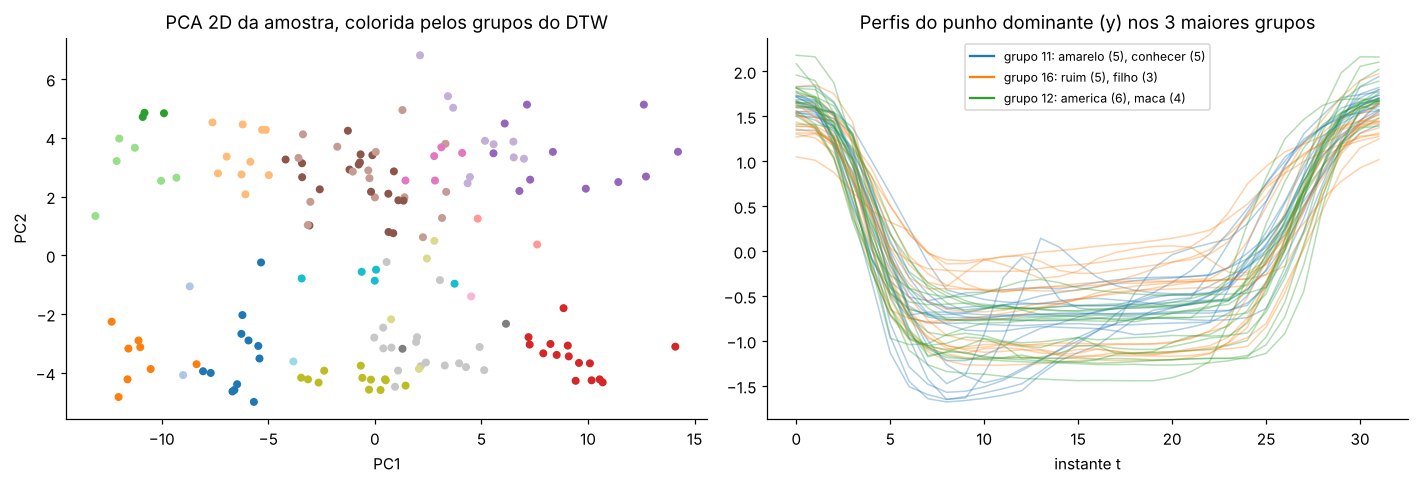

In [16]:
Z = linkage(squareform(D_dtw, checks=False), "complete")
grupos_dtw = fcluster(Z, 20, "maxclust")
fig, ax = plt.subplots(figsize=(15, 4))
dendrogram(Z, labels=classes[y[amostra]], leaf_font_size=5, color_threshold=Z[-19, 2], ax=ax)
ax.set_title("Dendrograma (DTW, ligação completa) — rótulos = palavra verdadeira"); ax.set_ylabel("distância DTW")
plt.tight_layout(); salvar_fig("dendrograma_dtw"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
pc = PCA(2, random_state=SEED).fit_transform(S.reshape(len(S), -1))
axs[0].scatter(pc[:, 0], pc[:, 1], c=grupos_dtw, cmap="tab20", s=18)
axs[0].set_title("PCA 2D da amostra, colorida pelos grupos do DTW"); axs[0].set_xlabel("PC1"); axs[0].set_ylabel("PC2")
maiores = pd.Series(grupos_dtw).value_counts().index[:3]
for g, cor in zip(maiores, ["tab:blue", "tab:orange", "tab:green"]):
    for s_ in S[grupos_dtw == g][:, :, 1]:
        axs[1].plot(s_, color=cor, alpha=.35, lw=1)
    comp = pd.Series(classes[y[amostra][grupos_dtw == g]]).value_counts().head(2)
    axs[1].plot([], color=cor, label=f"grupo {g}: " + ", ".join(f"{p} ({n})" for p, n in comp.items()))
axs[1].set_title("Perfis do punho dominante (y) nos 3 maiores grupos"); axs[1].set_xlabel("instante t"); axs[1].legend(fontsize=8)
plt.tight_layout(); salvar_fig("clusters_dtw"); plt.show()

**Leitura:** o DTW agrupa as palavras um pouco melhor que a distância euclidiana. Isso confirma que parte da diferença entre vídeos da mesma palavra é **defasagem temporal**, e não forma. Mesmo assim, o ARI fica baixo: só a trajetória da mão não basta para separar 20 palavras, porque várias têm o mesmo caminho e diferem na **configuração de mão** (os blocos `fdom` e `foutra`). Por isso o classificador de referência **1-NN + DTW** (notebook 02) vai usar todos os canais.

## 11. Síntese para o artigo

In [17]:
r = res.groupby("modelo")[["acuracia", "acuracia_balanceada", "f1_macro"]].mean()
print(f"Random Forest : acurácia {r.loc['Random Forest', 'acuracia']:.1%} | F1 macro {r.loc['Random Forest', 'f1_macro']:.1%}")
print(f"XGBoost       : acurácia {r.loc['XGBoost', 'acuracia']:.1%} | F1 macro {r.loc['XGBoost', 'f1_macro']:.1%}")
print(f"Majoritária   : acurácia {r.loc['Classe majoritária', 'acuracia']:.1%} (acaso = {1 / 20:.0%})")
ari_completa = ari[ari.ligacao == "complete"].set_index("distancia").ARI.to_dict()
print("ARI (ligação completa):", ari_completa)

Random Forest : acurácia 75.5% | F1 macro 74.3%
XGBoost       : acurácia 73.9% | F1 macro 72.3%
Majoritária   : acurácia 5.2% (acaso = 5%)
ARI (ligação completa): {'DTW': 0.178, 'Euclidiana': 0.144}


- **Natureza temporal:** séries curtas (32 instantes, ~10 Hz no trecho ativo), multivariadas (321 canais), sem covariáveis exógenas, com forte autocorrelação (ACF de lag 1 ≈ 0,8–0,9) e conteúdo concentrado em baixas frequências.
- **Estacionariedade:** cada série é um evento transitório (ida e volta da mão), não estacionário nem em nível nem na 1ª diferença. Com 32 pontos, ADF e KPSS têm pouco poder e discordam. Na classificação, essa forma é a própria informação; o problema real é a mudança de distribuição **entre pessoas**.
- **Ruído:** as mãos concentram mais energia em alta frequência (tremor do MediaPipe e falhas de detecção). Isso motiva a ablação com média móvel e FFT.
- **Atributos ergódicos + árvores:** RF e XGBoost reconhecem a palavra muito acima do acaso (5%) e da classe majoritária, para pessoas nunca vistas. Isso serve de referência forte para os modelos sequenciais. O RF, sem ajuste nenhum, ficou à frente do XGBoost em 3 das 4 rodadas e na média.
- **Agrupamento:** o DTW supera a distância euclidiana, evidência de defasagens temporais entre sinalizantes, mas a trajetória sozinha não separa as palavras.